# 06 — Recorte dos dados: mapeamento VideoID → conteúdo/QP

Identifica o padrão das configurações de qualidade por VideoID e gera o recorte só com as configurações uniformes (QP 15, 22, 32, 42).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA_ROOT = Path("RCQoEA-360VR-Dataset")
QOE_DIR = DATA_ROOT / "QoE_Annotation_Data"
DURACAO_VIDEO = 30

## Carregamento do QoEC contínuo

Tempo normalizado pela posição da amostra no vídeo de 30 s. Bloco definido pela ordem cronológica das sessões de cada participante.

In [2]:
registros = []
for arq in (QOE_DIR / "Continuous_QoE_Score").glob("RCQoE_P*_V*_*.txt"):
    p, v, ts = re.search(r"_P(\d+)_V(\d+)_(\d+T\d+)", arq.name).groups()
    serie = pd.read_csv(arq, sep=";", skipinitialspace=True, usecols=[0, 2])
    serie.columns = ["amostra", "qoec"]
    serie["t"] = serie["amostra"] / (len(serie) - 1) * DURACAO_VIDEO
    serie["ParticipantID"], serie["VideoID"], serie["inicio"] = int(p), int(v), ts
    registros.append(serie)

qoec = pd.concat(registros, ignore_index=True)

ordem = (qoec[["ParticipantID", "VideoID", "inicio"]].drop_duplicates()
         .sort_values(["ParticipantID", "inicio"]))
ordem["posicao"] = ordem.groupby("ParticipantID").cumcount() + 1
ordem["bloco"] = np.where(ordem["posicao"] <= 20, 1, 2)

qoec.shape

(149185, 6)

## MOS e tabela por par participante × vídeo

In [3]:
mos = pd.read_csv(QOE_DIR / "Post_Video_QoE_Score" / "post_video_mos_ratings.csv")
mos.columns = ["ParticipantID", "VideoID", "MOS"]

por_video = (qoec.groupby(["ParticipantID", "VideoID"])["qoec"].mean().rename("QoEC")
             .reset_index()
             .merge(mos, on=["ParticipantID", "VideoID"])
             .merge(ordem[["ParticipantID", "VideoID", "posicao", "bloco"]],
                    on=["ParticipantID", "VideoID"]))

por_video.head()

,ParticipantID,VideoID,QoEC,MOS,posicao,bloco
0,1,1,0.000000,5,18,1
1,1,2,0.494165,5,29,2
2,1,3,0.000000,4,19,1
3,1,4,0.101971,1,8,1
4,1,5,0.372283,2,30,2


## QoEC e MOS médios por VideoID

Linhas tracejadas a cada 4 vídeos, linhas sólidas a cada 8.

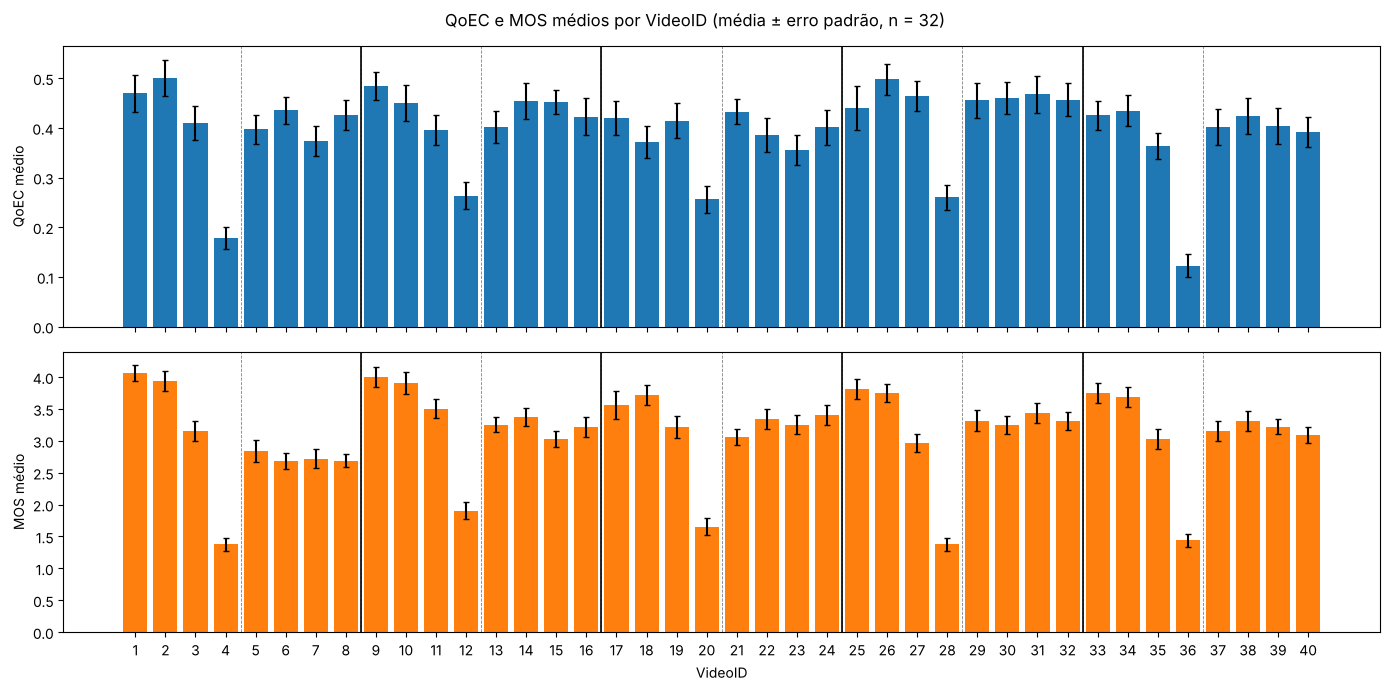

In [4]:
resumo = por_video.groupby("VideoID")[["QoEC", "MOS"]].agg(["mean", "sem"])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col, cor in zip(axes, ["QoEC", "MOS"], ["tab:blue", "tab:orange"]):
    ax.bar(resumo.index, resumo[(col, "mean")], yerr=resumo[(col, "sem")], color=cor, capsize=2)
    ax.set_ylabel(f"{col} médio")
    for x in np.arange(4.5, 40, 4):
        ax.axvline(x, color="gray", lw=0.6, ls="--")
    for x in np.arange(8.5, 40, 8):
        ax.axvline(x, color="black", lw=1.2)
axes[1].set_xlabel("VideoID")
axes[1].set_xticks(range(1, 41))
fig.suptitle("QoEC e MOS médios por VideoID (média ± erro padrão, n = 32)")
fig.tight_layout()
plt.show()

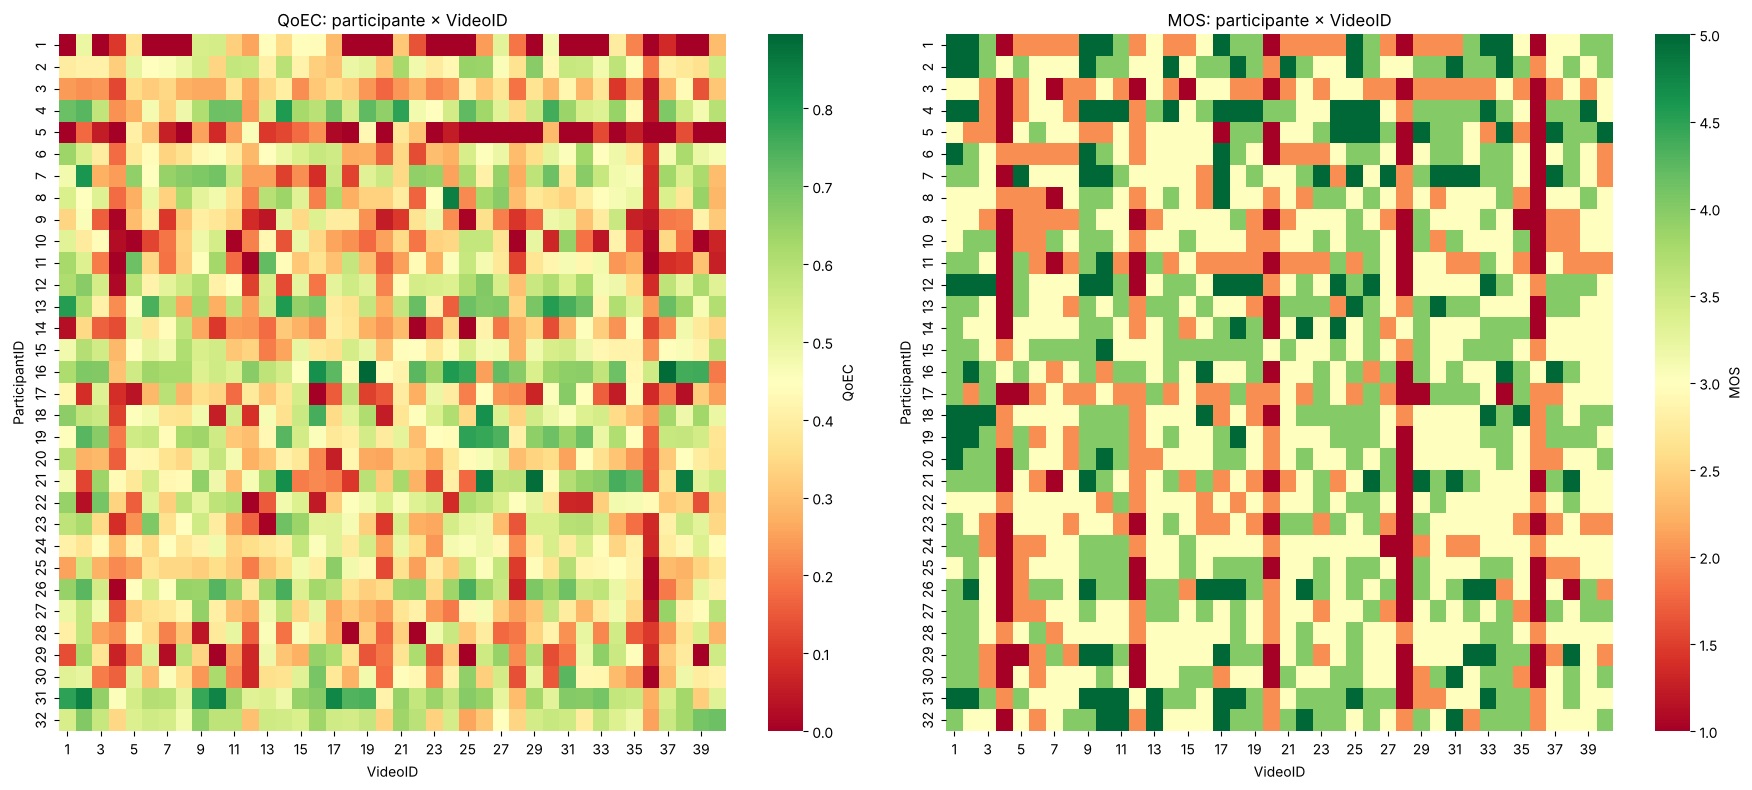

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, col in zip(axes, ["QoEC", "MOS"]):
    mat = por_video.pivot(index="ParticipantID", columns="VideoID", values=col)
    sns.heatmap(mat, cmap="RdYlGn", ax=ax, cbar_kws={"label": col})
    ax.set_title(f"{col}: participante × VideoID")
fig.tight_layout()
plt.show()

## Mapeamento

O pior vídeo aparece sempre na 4ª posição de cada grupo de 8 (V4, V12, V20, V28, V36). Hipótese: cada grupo de 8 é um conteúdo; posições 1–4 são uniformes (QP 15, 22, 32, 42) e 5–8 são as configurações em tiles.

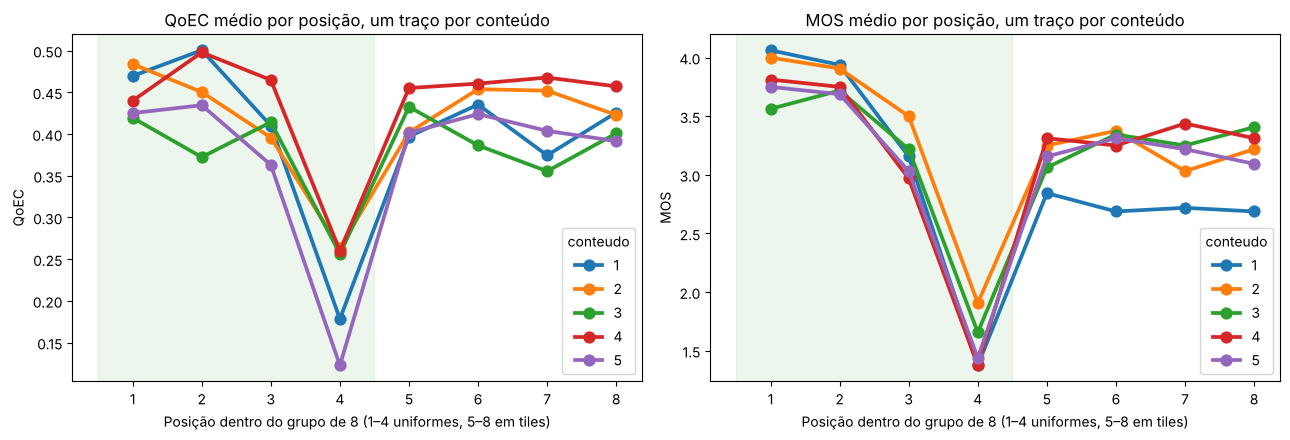

In [6]:
QP_POR_POSICAO = {1: 15, 2: 22, 3: 32, 4: 42}

por_video["conteudo"] = (por_video["VideoID"] - 1) // 8 + 1
por_video["posicao_no_grupo"] = (por_video["VideoID"] - 1) % 8 + 1
por_video["uniforme"] = por_video["posicao_no_grupo"] <= 4
por_video["QP"] = por_video["posicao_no_grupo"].map(QP_POR_POSICAO)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, col in zip(axes, ["QoEC", "MOS"]):
    sns.pointplot(data=por_video, x="posicao_no_grupo", y=col, hue="conteudo",
                  errorbar=None, palette="tab10", ax=ax)
    ax.axvspan(-0.5, 3.5, color="green", alpha=0.07)
    ax.set_xlabel("Posição dentro do grupo de 8 (1–4 uniformes, 5–8 em tiles)")
    ax.set_title(f"{col} médio por posição, um traço por conteúdo")
fig.tight_layout()
plt.show()

## Recorte: configurações uniformes (5 conteúdos × 4 QPs)

In [7]:
recorte = por_video[por_video["uniforme"]].copy()
qoec_recorte = qoec.merge(recorte[["ParticipantID", "VideoID", "conteudo", "QP", "MOS", "bloco"]],
                          on=["ParticipantID", "VideoID"])

recorte.groupby("QP")[["QoEC", "MOS"]].agg(["mean", "std", "count"]).round(2)

QoEC               MOS            
      mean   std count  mean   std count
QP                                      
15.0  0.45  0.20   160  3.84  0.94   160
22.0  0.45  0.19   160  3.80  0.87   160
32.0  0.41  0.18   160  3.18  0.88   160
42.0  0.22  0.15   160  1.55  0.68   160

In [8]:
recorte.groupby(["conteudo", "QP"])["MOS"].mean().unstack().round(2)

QP,15.0,22.0,32.0,42.0
conteudo,,,,
1,4.06,3.94,3.16,1.38
2,4.00,3.91,3.50,1.91
3,3.56,3.72,3.22,1.66
4,3.81,3.75,2.97,1.38
5,3.75,3.69,3.03,1.44


## Exportação

In [9]:
recorte.to_csv("recorte_uniforme_por_video.csv", index=False)
qoec_recorte.to_csv("recorte_uniforme_qoec_serie.csv", index=False)